# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis

In [2]:
import os
os.makedirs('images', exist_ok=True)

df = pd.read_csv('cleaned_aviation_data.csv', low_memory=False)
print(df.shape)
df[['Make', 'Plane.Type', 'Total.Passengers', 'Fatal.Serious.Fraction', 'Destroyed']].head()

(59888, 32)


,Make,Plane.Type,Total.Passengers,Fatal.Serious.Fraction,Destroyed
0,CESSNA,CESSNA 182P,4.0,0.0,0
1,CESSNA,CESSNA 182RG,2.0,0.0,0
2,CESSNA,CESSNA 182P,1.0,0.0,0
3,PIPER,PIPER PA28R200,2.0,0.0,0
4,CESSNA,CESSNA 140,2.0,0.0,0


**Note:** the data only has accidents, so all the rates below mean "what happens *when* there is an accident". It does not tell us how often a make has accidents.

## Explore safety metrics across models/makes

The data has no column for aircraft size, so I use the number of people on board. If I labelled each accident by its own passenger count, a half-empty 737 would count as small. So I label each **plane type** once: if the 90th percentile of its people on board is 20 or more, the type is **Large**, otherwise **Small**. (I used the 90th percentile and not the maximum so that one wrong value in the data cannot change a whole type.)

To make sure I have enough samples, I only compare makes with at least **30 accidents** in their size group and plane types with at least **10 accidents**. The `count` column is shown in every table.

In [3]:
df['Plane.Size'] = np.where(df['Plane.Type'].map(df.groupby('Plane.Type')['Total.Passengers'].quantile(0.9)) >= 20, 'Large', 'Small')

small = df[df['Plane.Size'] == 'Small']
large = df[df['Plane.Size'] == 'Large']
print(df['Plane.Size'].value_counts())

# a quick check that the split makes sense
print(large['Plane.Type'].value_counts().head(6))
print(small['Plane.Type'].value_counts().head(6))

Plane.Size
Small    58160
Large     1728
Name: count, dtype: int64
Plane.Type
BOEING 737                121
MCDONNELL DOUGLAS DC3      37
BOMBARDIER CL6002B19       37
FAIRCHILD SA227AC          35
BEECH 1900C                33
MCDONNELL DOUGLAS MD11     32
Name: count, dtype: int64
Plane.Type
CESSNA 152       2211
CESSNA 172       1614
CESSNA 172N      1088
PIPER PA28140     925
CESSNA 172M       786
CESSNA 150        742
Name: count, dtype: int64


In [4]:
def summary_table(data, column, min_count):
    """count, mean fatal/serious fraction and destroyed rate for each group, keeping groups with enough accidents"""
    table = data.groupby(column).agg(count=('Destroyed', 'size'),
                                     mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                                     destroyed_rate=('Destroyed', 'mean'))
    return table[table['count'] >= min_count]

make_small = summary_table(small, 'Make', 30)
make_large = summary_table(large, 'Make', 30)
print('Makes with at least 30 accidents: small', len(make_small), ', large', len(make_large))

# overall averages to compare against
print(df.groupby('Plane.Size')[['Fatal.Serious.Fraction', 'Destroyed']].mean().round(3))

Makes with at least 30 accidents: small 53 , large 9
            Fatal.Serious.Fraction  Destroyed
Plane.Size                                   
Large                        0.124      0.135
Small                        0.276      0.214


#### Analyzing Makes

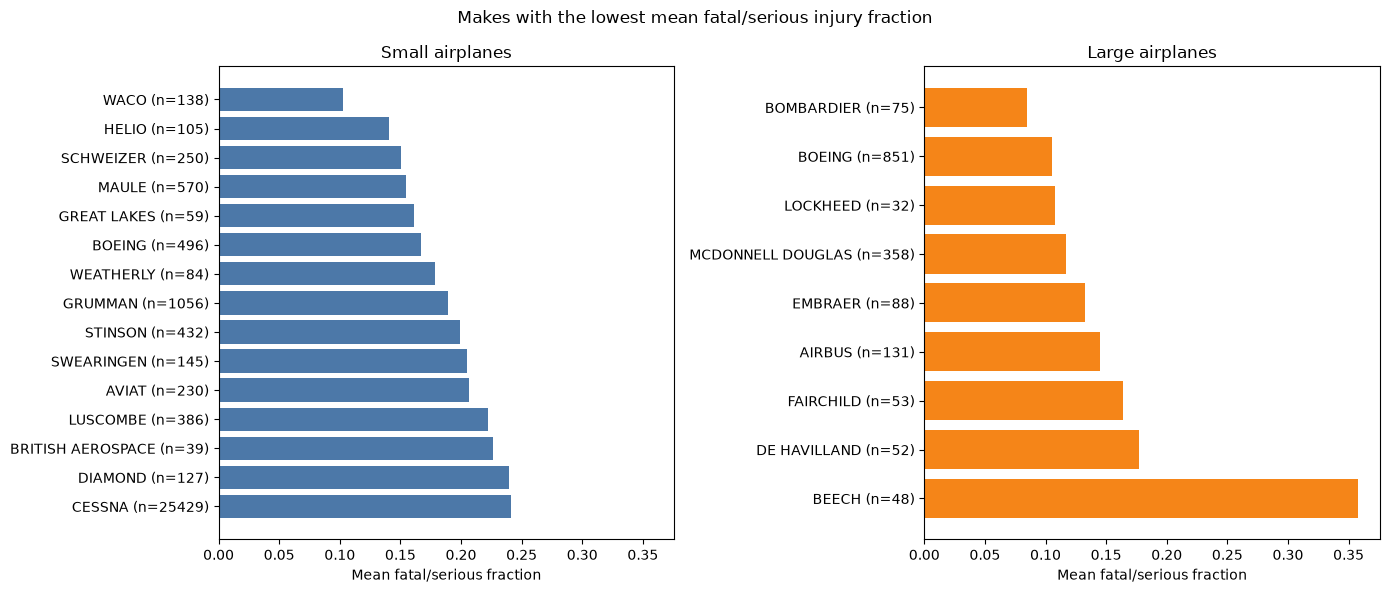

,count,mean_fatal_serious,destroyed_rate
Make,,,
WACO,138,0.103,0.087
HELIO,105,0.141,0.124
SCHWEIZER,250,0.151,0.160
MAULE,570,0.155,0.093
GREAT LAKES,59,0.161,0.136
BOEING,496,0.167,0.127
WEATHERLY,84,0.179,0.214
GRUMMAN,1056,0.189,0.245
STINSON,432,0.199,0.130


In [5]:
top_small = make_small.sort_values('mean_fatal_serious').head(15)
top_large = make_large.sort_values('mean_fatal_serious').head(15)   # only a few large makes have enough accidents

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, table, color, title in [(axes[0], top_small, '#4C78A8', 'Small airplanes'),
                                (axes[1], top_large, '#F58518', 'Large airplanes')]:
    labels = table.index + ' (n=' + table['count'].astype(str) + ')'
    ax.barh(labels, table['mean_fatal_serious'], color=color)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel('Mean fatal/serious fraction')
plt.suptitle('Makes with the lowest mean fatal/serious injury fraction')
plt.tight_layout()
plt.savefig('images/lowest_injury_makes.png', dpi=150)
plt.show()

top_small.round(3)

In [6]:
top_large.round(3)

,count,mean_fatal_serious,destroyed_rate
Make,,,
BOMBARDIER,75,0.085,0.080
BOEING,851,0.105,0.110
LOCKHEED,32,0.108,0.156
MCDONNELL DOUGLAS,358,0.117,0.142
EMBRAER,88,0.133,0.125
AIRBUS,131,0.145,0.160
FAIRCHILD,53,0.164,0.208
DE HAVILLAND,52,0.177,0.212
BEECH,48,0.358,0.292


**Distribution of injury rates: small makes**

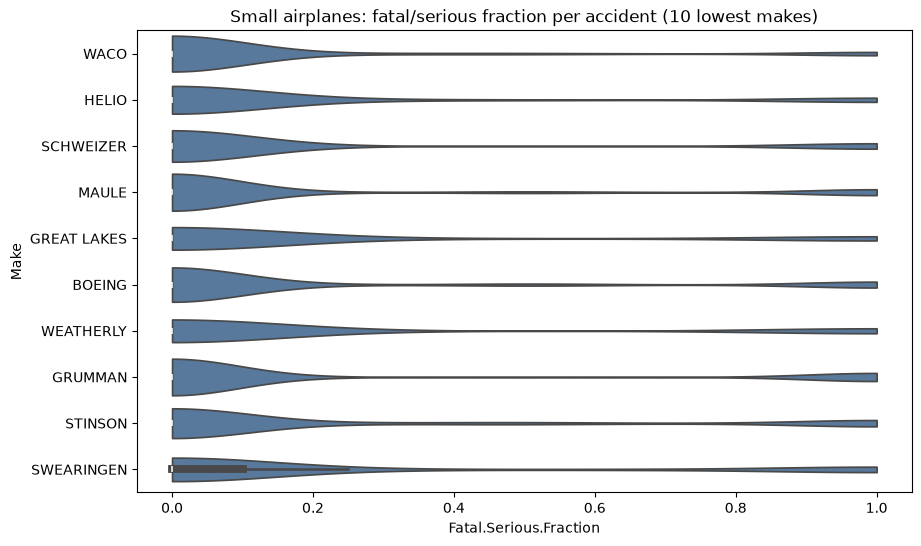

,nobody_hurt,everybody_hurt
Make,,
WACO,0.87,0.08
HELIO,0.83,0.12
SCHWEIZER,0.84,0.14
MAULE,0.82,0.13
GREAT LAKES,0.83,0.15
BOEING,0.80,0.14
WEATHERLY,0.82,0.18
GRUMMAN,0.80,0.18
STINSON,0.76,0.16


In [7]:
top10_small = make_small.sort_values('mean_fatal_serious').head(10).index

plt.figure(figsize=(10, 6))
sns.violinplot(data=small[small['Make'].isin(top10_small)], y='Make', x='Fatal.Serious.Fraction',
               order=top10_small, cut=0, color='#4C78A8')
plt.title('Small airplanes: fatal/serious fraction per accident (10 lowest makes)')
plt.savefig('images/violin_small_makes.png', dpi=150)
plt.show()

# share of accidents where nobody / everybody was fatally or seriously hurt
sub = small[small['Make'].isin(top10_small)]
pd.DataFrame({'nobody_hurt': sub.groupby('Make')['Fatal.Serious.Fraction'].apply(lambda s: (s == 0).mean()),
              'everybody_hurt': sub.groupby('Make')['Fatal.Serious.Fraction'].apply(lambda s: (s == 1).mean())}).loc[top10_small].round(2)

**Distribution of injury rates: large makes**

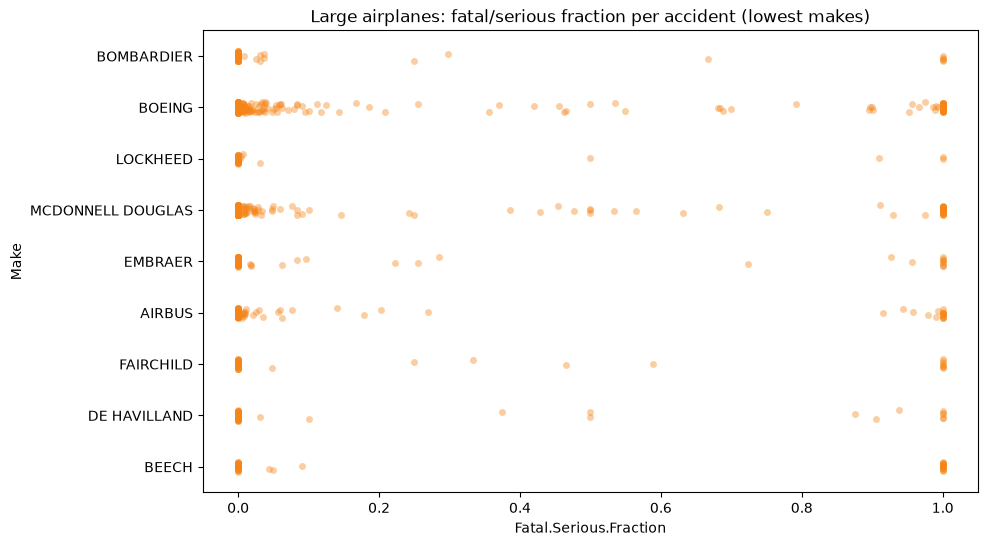

In [8]:
top10_large = make_large.sort_values('mean_fatal_serious').head(10).index

plt.figure(figsize=(10, 6))
sns.stripplot(data=large[large['Make'].isin(top10_large)], y='Make', x='Fatal.Serious.Fraction',
              order=top10_large, alpha=0.4, color='#F58518')
plt.title('Large airplanes: fatal/serious fraction per accident (lowest makes)')
plt.savefig('images/strip_large_makes.png', dpi=150)
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.**

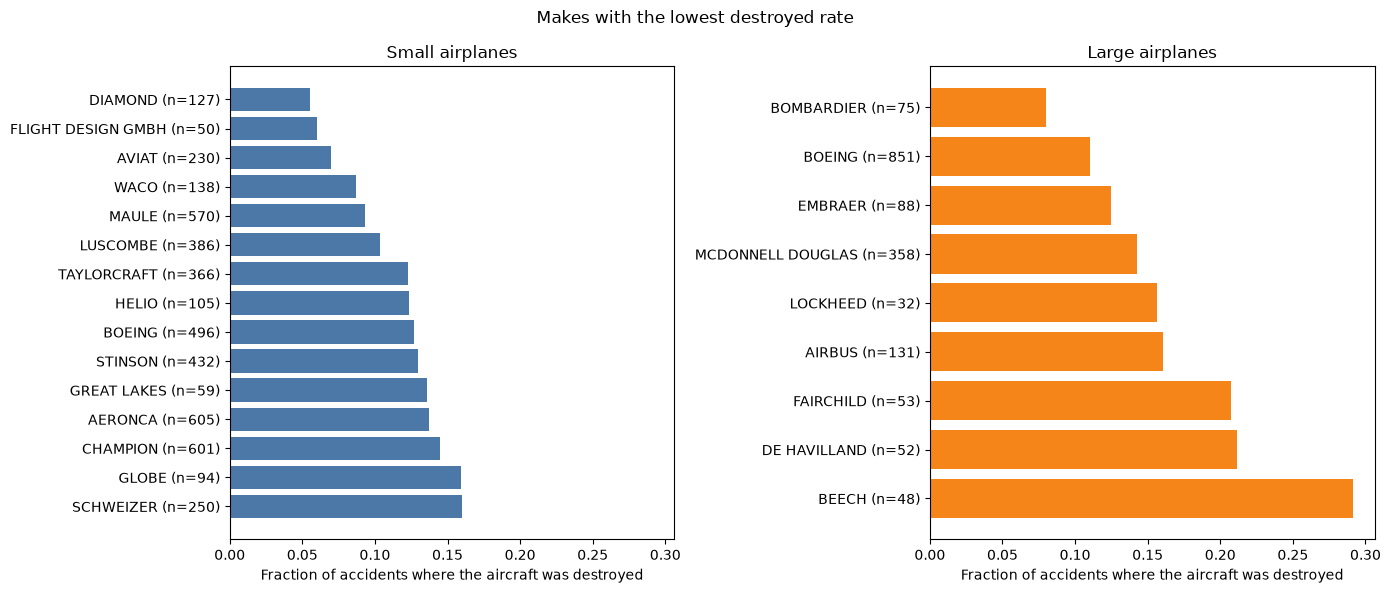

,count,mean_fatal_serious,destroyed_rate
Make,,,
DIAMOND,127,0.240,0.055
FLIGHT DESIGN GMBH,50,0.370,0.060
AVIAT,230,0.207,0.070
WACO,138,0.103,0.087
MAULE,570,0.155,0.093
LUSCOMBE,386,0.222,0.104
TAYLORCRAFT,366,0.292,0.123
HELIO,105,0.141,0.124
BOEING,496,0.167,0.127


In [9]:
dest_small = make_small.sort_values('destroyed_rate').head(15)
dest_large = make_large.sort_values('destroyed_rate').head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, table, color, title in [(axes[0], dest_small, '#4C78A8', 'Small airplanes'),
                                (axes[1], dest_large, '#F58518', 'Large airplanes')]:
    labels = table.index + ' (n=' + table['count'].astype(str) + ')'
    ax.barh(labels, table['destroyed_rate'], color=color)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel('Fraction of accidents where the aircraft was destroyed')
plt.suptitle('Makes with the lowest destroyed rate')
plt.tight_layout()
plt.savefig('images/lowest_destroyed_makes.png', dpi=150)
plt.show()

dest_small.round(3)

In [10]:
dest_large.round(3)

,count,mean_fatal_serious,destroyed_rate
Make,,,
BOMBARDIER,75,0.085,0.080
BOEING,851,0.105,0.110
EMBRAER,88,0.133,0.125
MCDONNELL DOUGLAS,358,0.117,0.142
LOCKHEED,32,0.108,0.156
AIRBUS,131,0.145,0.160
FAIRCHILD,53,0.164,0.208
DE HAVILLAND,52,0.177,0.212
BEECH,48,0.358,0.292


In [11]:
# makes that do well on both measures: add up the rank on each (lowest total is best)
for name, table in [('Small', make_small), ('Large', make_large)]:
    table = table.copy()
    table['rank_total'] = table['mean_fatal_serious'].rank() + table['destroyed_rate'].rank()
    print(name)
    print(table.sort_values('rank_total').head(8).round(3))
    print()

Small
             count  mean_fatal_serious  destroyed_rate  rank_total
Make                                                              
WACO           138               0.103           0.087         5.0
MAULE          570               0.155           0.093         9.0
HELIO          105               0.141           0.124        10.0
AVIAT          230               0.207           0.070        14.0
DIAMOND        127               0.240           0.055        15.0
BOEING         496               0.167           0.127        15.0
GREAT LAKES     59               0.161           0.136        16.0
LUSCOMBE       386               0.222           0.104        18.0

Large
                   count  mean_fatal_serious  destroyed_rate  rank_total
Make                                                                    
BOMBARDIER            75               0.085           0.080         2.0
BOEING               851               0.105           0.110         4.0
LOCKHEED              32 

#### Provide a short discussion on your findings for your summary statistics and plots:

**Overall averages:** small airplanes have a mean fatal/serious fraction of 0.276 and a destroyed rate of 0.214. For large airplanes it is 0.124 and 0.135. In most accidents nobody is fatally or seriously hurt (the violins are tallest at 0), but in about 8-18% of accidents everybody on board is (the small bump at 1.0), so the mean depends on how often an accident becomes a total loss.

**Small airplanes**
- Lowest fatal/serious fraction: **Waco** (0.103, n=138), **Helio** (0.141, n=105), **Schweizer** (0.151, n=250) and **Maule** (0.155, n=570). Cessna has by far the most accidents (n=25,429) and is at 0.241, just below the small-plane average.
- Lowest destroyed rate: **Diamond** (0.055, n=127), **Aviat** (0.070, n=230), **Waco** (0.087) and **Maule** (0.093).
- Doing well on both measures: **Waco, Maule, Helio, Aviat, Diamond, Schweizer**. Maule and Aviat have the most accidents behind them (570 and 230), so I trust them more than Waco, Helio or Great Lakes, which only have 59-138 accidents.
- Flight Design has a low destroyed rate (0.060) but a high fatal/serious fraction (0.370) and only 50 accidents, so I would not recommend it.
- Many of the best makes (Waco, Stearman/Boeing, Stinson, Luscombe) are old, slow planes. Part of their good result may come from how they are flown and not only from the design.

**Large airplanes** (only 9 makes have at least 30 accidents)
- **Bombardier** (0.085 / 0.080, n=75), **Boeing** (0.105 / 0.110, n=851), **McDonnell Douglas** (0.117 / 0.142, n=358), **Embraer** (0.133 / 0.125, n=88) and **Airbus** (0.145 / 0.160, n=131) are the lowest.
- The differences between these five are small, so I would not say one is clearly better than another. Boeing and McDonnell Douglas have the biggest samples and still rank at the top, so they are the most reliable. Lockheed (n=32) and Bombardier (n=75) look good but have few accidents.
- **Beech** (the 1900 commuter, n=48) is much worse at 0.358 / 0.292. Fairchild and De Havilland (about 50 accidents each) are also higher at 0.16-0.21.

**Recommendation:** small - Maule, Aviat, Diamond and Schweizer (Stinson and Luscombe next). Large - Boeing, McDonnell Douglas, Embraer, Airbus and Bombardier.

### Analyze plane types

**Larger planes**

44 large plane types with at least 10 accidents


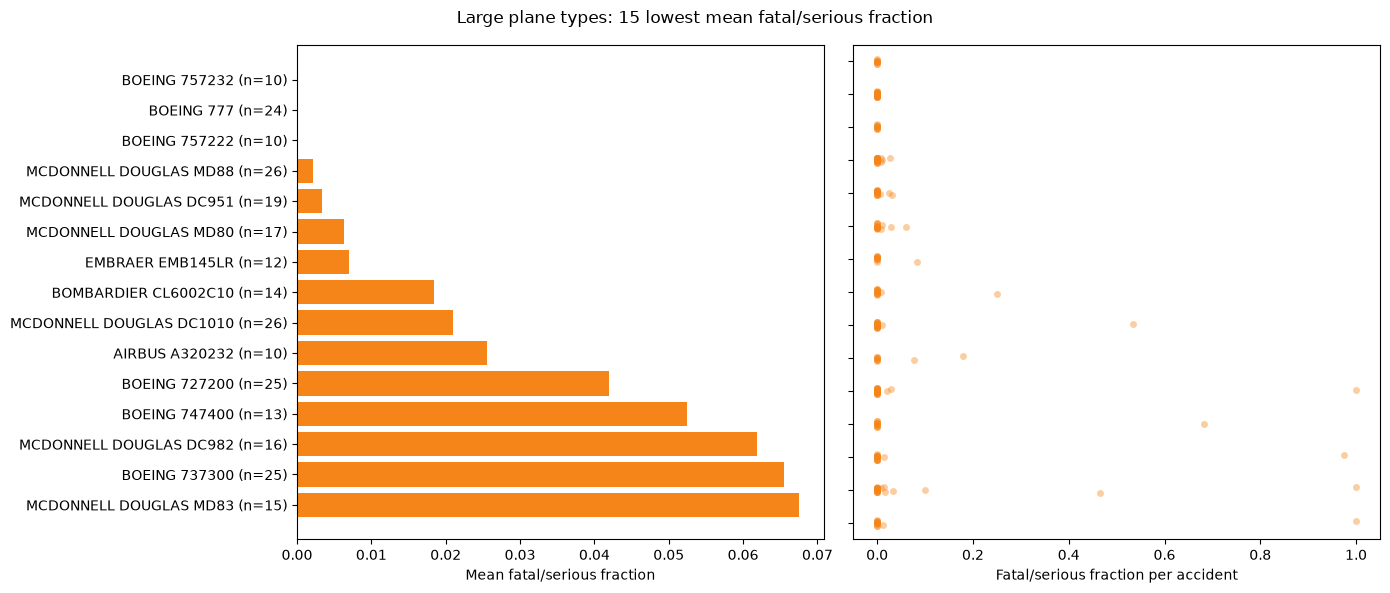

,Make,Plane.Type,count,mean_fatal_serious,destroyed_rate
20,BOEING,BOEING 757232,10,0.000,0.000
22,BOEING,BOEING 777,24,0.000,0.042
19,BOEING,BOEING 757222,10,0.000,0.000
43,MCDONNELL DOUGLAS,MCDONNELL DOUGLAS MD88,26,0.002,0.000
37,MCDONNELL DOUGLAS,MCDONNELL DOUGLAS DC951,19,0.003,0.053
40,MCDONNELL DOUGLAS,MCDONNELL DOUGLAS MD80,17,0.006,0.000
28,EMBRAER,EMBRAER EMB145LR,12,0.007,0.000
24,BOMBARDIER,BOMBARDIER CL6002C10,14,0.018,0.000
32,MCDONNELL DOUGLAS,MCDONNELL DOUGLAS DC1010,26,0.021,0.038
1,AIRBUS,AIRBUS A320232,10,0.026,0.000


In [12]:
type_large = summary_table(large, ['Make', 'Plane.Type'], 10).reset_index()
print(len(type_large), 'large plane types with at least 10 accidents')
top_type_large = type_large.sort_values('mean_fatal_serious').head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
labels = top_type_large['Plane.Type'] + ' (n=' + top_type_large['count'].astype(str) + ')'
axes[0].barh(labels, top_type_large['mean_fatal_serious'], color='#F58518')
axes[0].invert_yaxis()
axes[0].set_xlabel('Mean fatal/serious fraction')

sns.stripplot(data=large[large['Plane.Type'].isin(top_type_large['Plane.Type'])], y='Plane.Type', x='Fatal.Serious.Fraction',
              order=top_type_large['Plane.Type'], alpha=0.4, color='#F58518', ax=axes[1])
axes[1].set_ylabel('')
axes[1].set_yticklabels([])
axes[1].set_xlabel('Fatal/serious fraction per accident')
plt.suptitle('Large plane types: 15 lowest mean fatal/serious fraction')
plt.tight_layout()
plt.savefig('images/large_plane_types.png', dpi=150)
plt.show()

top_type_large.round(3)

**Smaller planes**
- only the plane types made by the 10 makes with the lowest mean fatal/serious fraction

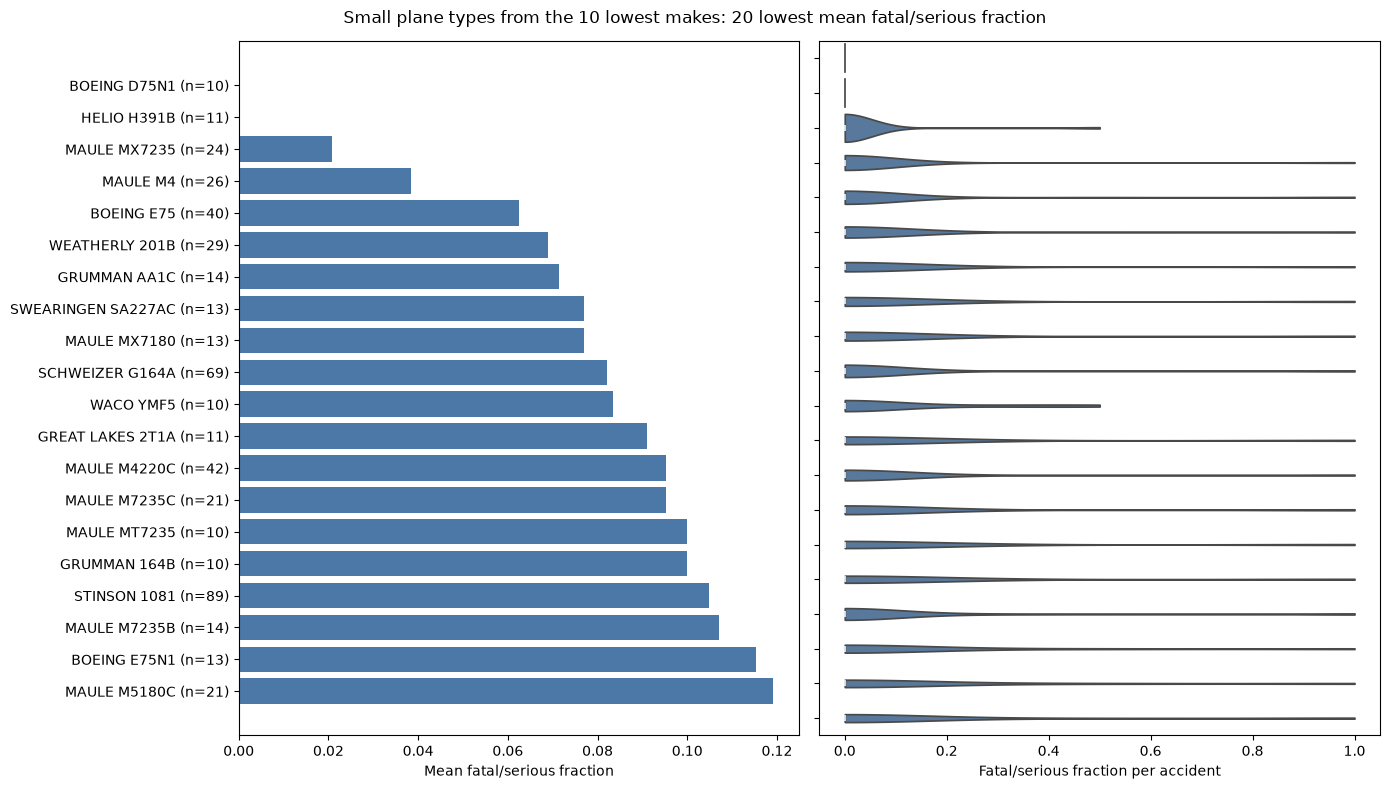

,Make,Plane.Type,count,mean_fatal_serious,destroyed_rate
165,BOEING,BOEING D75N1,10,0.000,0.100
460,HELIO,HELIO H391B,11,0.000,0.091
489,MAULE,MAULE MX7235,24,0.021,0.042
474,MAULE,MAULE M4,26,0.038,0.038
166,BOEING,BOEING E75,40,0.062,0.100
677,WEATHERLY,WEATHERLY 201B,29,0.069,0.103
441,GRUMMAN,GRUMMAN AA1C,14,0.071,0.357
666,SWEARINGEN,SWEARINGEN SA227AC,13,0.077,0.077
488,MAULE,MAULE MX7180,13,0.077,0.000
651,SCHWEIZER,SCHWEIZER G164A,69,0.082,0.145


In [13]:
type_small = summary_table(small, ['Make', 'Plane.Type'], 10).reset_index()
type_small = type_small[type_small['Make'].isin(top10_small)]
top_type_small = type_small.sort_values('mean_fatal_serious').head(20)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
labels = top_type_small['Plane.Type'] + ' (n=' + top_type_small['count'].astype(str) + ')'
axes[0].barh(labels, top_type_small['mean_fatal_serious'], color='#4C78A8')
axes[0].invert_yaxis()
axes[0].set_xlabel('Mean fatal/serious fraction')

sns.violinplot(data=small[small['Plane.Type'].isin(top_type_small['Plane.Type'])], y='Plane.Type', x='Fatal.Serious.Fraction',
               order=top_type_small['Plane.Type'], cut=0, color='#4C78A8', ax=axes[1])
axes[1].set_ylabel('')
axes[1].set_yticklabels([])
axes[1].set_xlabel('Fatal/serious fraction per accident')
plt.suptitle('Small plane types from the 10 lowest makes: 20 lowest mean fatal/serious fraction')
plt.tight_layout()
plt.savefig('images/small_plane_types.png', dpi=150)
plt.show()

top_type_small.round(3)

### Discussion of Specific Airplane Types

Only plane types with at least 10 accidents are included. A type with a mean of exactly 0 may only have 10-25 accidents behind it, so those are good signs but not proof.

**Large types** (44 types have enough accidents). The lowest fatal/serious fractions are modern jetliners: **Boeing 777** (n=24, 0.000, destroyed 0.042), **MD-88** (n=26, 0.002, destroyed 0), **DC-9-51** (n=19, 0.003), **MD-80** (n=17, 0.006), **Embraer EMB-145LR** (n=12, 0.007), **Bombardier CL-600-2C10** (n=14, 0.018), **DC-10-10** (n=26, 0.021), **Boeing 727-200** (n=25, 0.042) and **Boeing 737-300** (n=25, 0.066). The Boeing 757 versions also have 0.000 but only 10 accidents each. The plain **Boeing 737** group is the largest sample (n=121) and is at about 0.13. The worst well-sampled large types are older or commuter aircraft: **Boeing 737-200** (about 0.38), **Airbus A320** (about 0.40, only about 15 accidents), **Beech 1900C** and the **DC-3** (about 0.34-0.37).

**Small types** (from the 10 makes with the lowest fatal/serious fraction). The best ones with a decent sample are the **Maule** types (MX-7-235 n=24, 0.021; M-4 n=26, 0.038; M-4-220C n=42, 0.095), **Boeing/Stearman E75** (n=40, 0.062), **Weatherly 201B** (n=29, 0.069), **Schweizer G-164A** (n=69, 0.082), and **Stinson 108-1** (n=89, 0.105). The **Grumman G-164A/B** (n=363 and 199) have a low fatal/serious fraction (about 0.12) but are destroyed in 22-25% of accidents. This shows why both measures are needed: the pilot usually survives, but the aircraft is often lost.

**Recommendation:** large - Boeing 777, 737-300, 727-200, McDonnell Douglas MD-80/MD-88/DC-9/DC-10, Embraer EMB-145 and Bombardier CL-600. Small - Maule M-4/M-7 types, Schweizer G-164A and Stinson 108-1.

### Exploring Other Variables

I chose **Weather Condition**, **Phase of Flight** and **Number of Engines**. For each one I compare the mean fatal/serious fraction and the destroyed rate for small and large airplanes. Groups with fewer than 30 accidents are left out and the number of accidents (`count`) is shown in the tables.

In [14]:
def factor_table(column):
    table = df.groupby([column, 'Plane.Size']).agg(count=('Destroyed', 'size'),
                                                   mean_fatal_serious=('Fatal.Serious.Fraction', 'mean'),
                                                   destroyed_rate=('Destroyed', 'mean'))
    return table[table['count'] >= 30].reset_index()

def plot_factor(table, column, title, filename, order=None, rotation=0):
    colors = {'Small': '#4C78A8', 'Large': '#F58518'}
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(data=table, x=column, y='mean_fatal_serious', hue='Plane.Size', order=order, palette=colors, ax=axes[0])
    sns.barplot(data=table, x=column, y='destroyed_rate', hue='Plane.Size', order=order, palette=colors, ax=axes[1])
    axes[0].set_ylabel('Mean fatal/serious fraction')
    axes[1].set_ylabel('Fraction destroyed')
    for ax in axes:
        ax.tick_params(axis='x', rotation=rotation)
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig('images/' + filename + '.png', dpi=150)
    plt.show()

### Factor 1: Weather Condition (VMC = good visibility, IMC = poor visibility / instrument conditions)

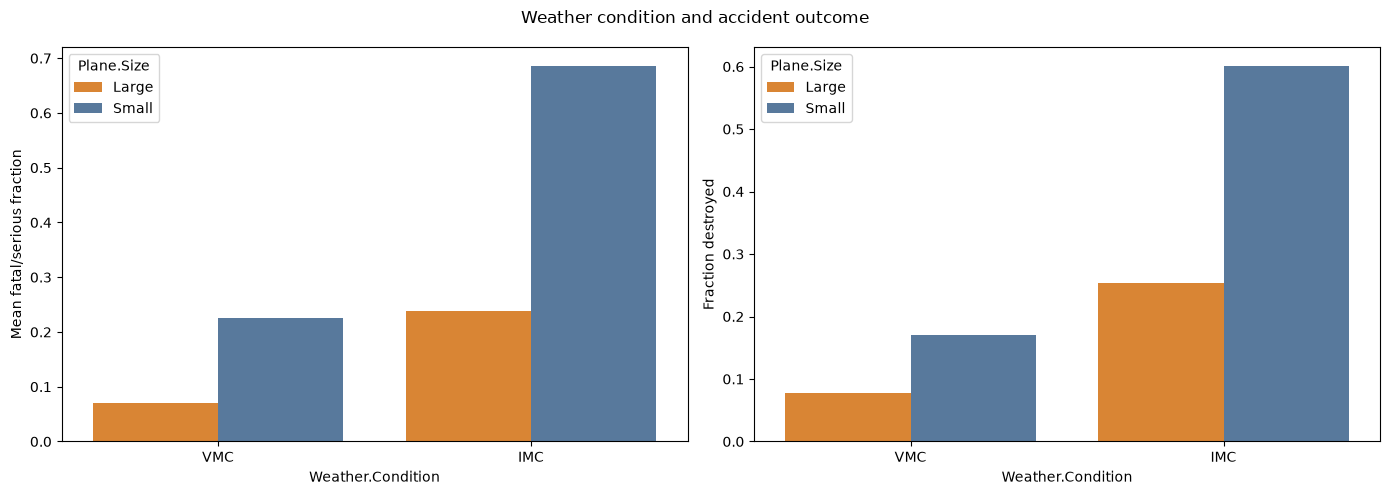

,Weather.Condition,Plane.Size,count,mean_fatal_serious,destroyed_rate
0,IMC,Large,236,0.238,0.254
1,IMC,Small,4572,0.686,0.601
2,VMC,Large,1045,0.071,0.078
3,VMC,Small,51509,0.225,0.170


In [15]:
weather = factor_table('Weather.Condition')
plot_factor(weather, 'Weather.Condition', 'Weather condition and accident outcome', 'factor_weather', order=['VMC', 'IMC'])
weather.round(3)

**Findings:** accidents in poor visibility (IMC) are much more severe than in good visibility (VMC), for both sizes.
- Small airplanes: fatal/serious fraction **0.686 in IMC (n=4,572) vs 0.225 in VMC (n=51,509)**. Destroyed rate 0.601 vs 0.170.
- Large airplanes: **0.238 in IMC (n=236) vs 0.071 in VMC (n=1,045)**. Destroyed rate 0.254 vs 0.078.
- So both measures are about 3 times higher in IMC, and the samples are big enough to trust this.
- A likely reason is that IMC accidents are often loss of control or flying into the ground at speed, while many VMC accidents are lower-speed events such as hard landings. This only tells us how bad an accident is, not how often IMC causes accidents.

### Factor 2: Phase of Flight

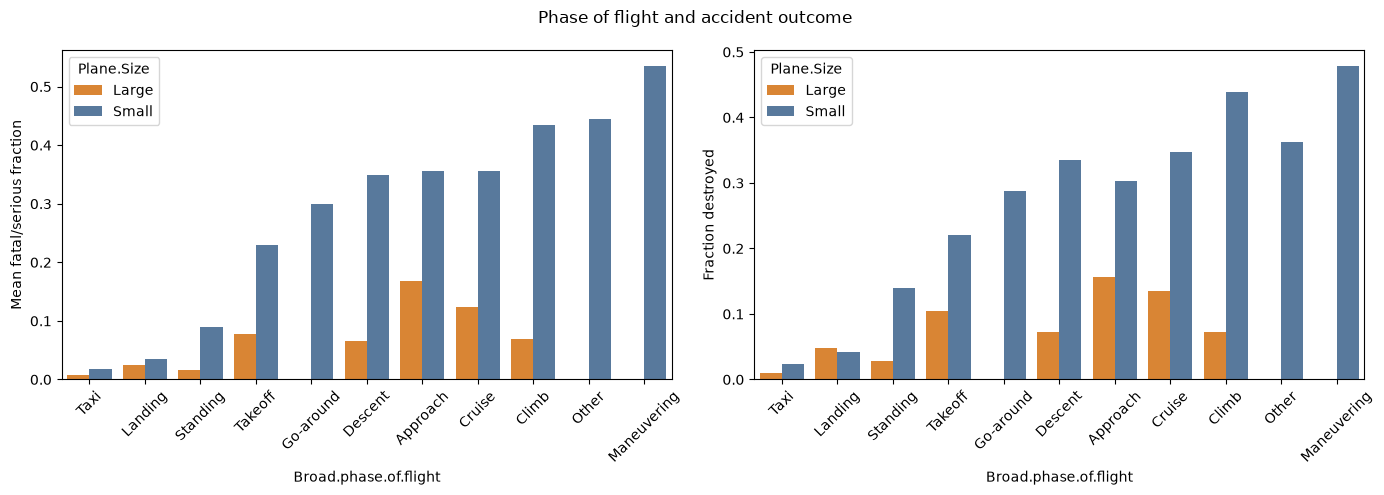

,Broad.phase.of.flight,Plane.Size,count,mean_fatal_serious,destroyed_rate
0,Approach,Large,96,0.169,0.156
1,Approach,Small,4485,0.356,0.303
2,Climb,Large,82,0.069,0.073
3,Climb,Small,1367,0.435,0.439
4,Cruise,Large,89,0.123,0.135
5,Cruise,Small,7043,0.355,0.347
6,Descent,Large,41,0.065,0.073
7,Descent,Small,1226,0.349,0.335
8,Go-around,Small,1161,0.299,0.288
9,Landing,Large,164,0.024,0.049


In [16]:
phase = factor_table('Broad.phase.of.flight')
phase_order = df.groupby('Broad.phase.of.flight')['Fatal.Serious.Fraction'].mean().sort_values().index
plot_factor(phase, 'Broad.phase.of.flight', 'Phase of flight and accident outcome', 'factor_phase', order=list(phase_order), rotation=45)
phase.round(3)

**Findings:** how bad an accident is depends a lot on the phase of flight.
- Small airplanes: **Maneuvering** is the worst (fatal/serious 0.536, destroyed 0.479, n=4,642), then **Climb** (0.435, n=1,367). Approach (0.356), Cruise (0.355) and Descent (0.349) are similar. Takeoff is lower (0.230, n=8,763). **Landing** (0.035, n=11,835) and **Taxi** (0.017, n=1,325) are the mildest even though landing is the most common phase for accidents.
- Large airplanes show the same pattern: Approach 0.169 (n=96), Cruise 0.123 (n=89), Takeoff 0.077 (n=181), Climb 0.069 (n=82), against Landing 0.024 (n=164), Standing 0.016 (n=72) and Taxi 0.007 (n=193). Several large phases have fewer than 100 accidents, so only the broad split between flying phases and ground/low-speed phases is reliable.
- Accidents on the ground or at low speed are mostly minor, while accidents in the air leave little room to recover. For the insurer, manoeuvring and low-level flying are the most expensive.

### Factor 3: Number of Engines

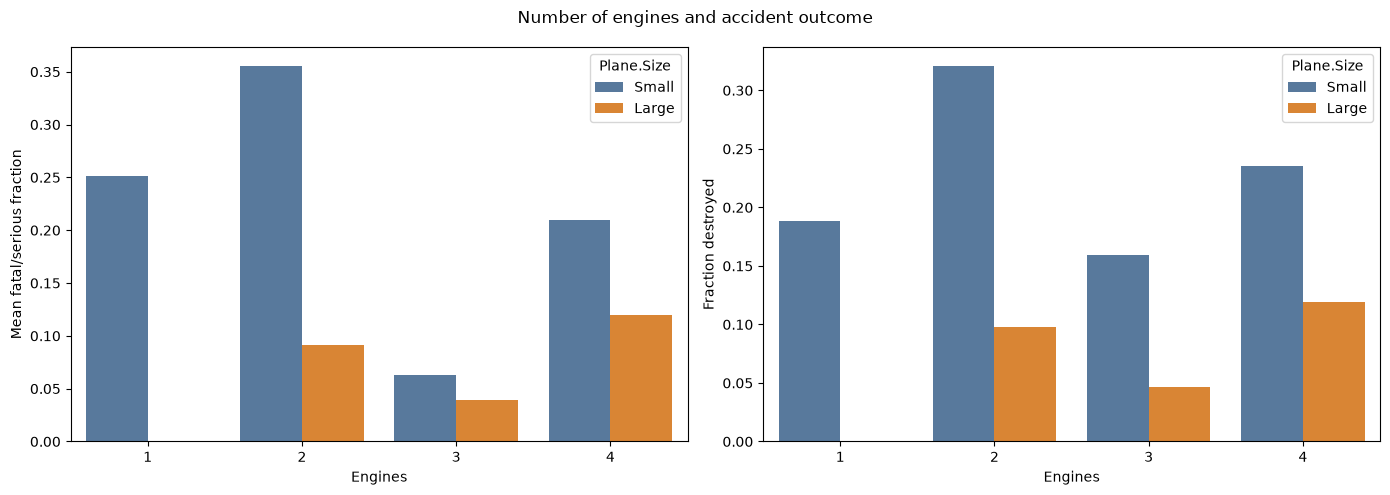

,Engines,Plane.Size,count,mean_fatal_serious,destroyed_rate
0,1,Small,48679,0.252,0.189
1,2,Large,947,0.091,0.098
2,2,Small,7206,0.356,0.321
3,3,Large,238,0.039,0.046
4,3,Small,44,0.062,0.159
5,4,Large,143,0.120,0.119
6,4,Small,140,0.210,0.236


In [17]:
df['Engines'] = df['Number.of.Engines'].astype(str).str.replace('.0', '', regex=False)
df.loc[df['Number.of.Engines'].isnull(), 'Engines'] = np.nan

engines = factor_table('Engines')
plot_factor(engines, 'Engines', 'Number of engines and accident outcome', 'factor_engines', order=['1', '2', '3', '4'])
engines.round(3)

**Findings:**
- Small airplanes: twin-engine planes do **worse** than single-engine ones when an accident happens. Fatal/serious fraction **0.356 (n=7,206) vs 0.252 (n=48,679)**, destroyed rate 0.321 vs 0.189. The 3- and 4-engine small planes have only 44 and 140 accidents, which is too few to say anything.
- Large airplanes: 3 engines looks best (0.039 / 0.046, n=238), then 2 engines (0.091 / 0.098, n=947) and 4 engines (0.120 / 0.119, n=143). The 3-engine group is mostly older types so I do not think this is caused by the engine count.
- More engines do not make a small plane safer once an accident happens. Twins are bigger, faster, carry more people and fly more in bad weather and for business, so this is probably not caused by the engines alone. I would not choose a make only based on its number of engines.

## Conclusion

If the client wants small airplanes that hold up well in an accident, Maule, Aviat, Diamond and Schweizer are the best supported choices. For large passenger planes, Boeing, McDonnell Douglas, Embraer, Airbus and Bombardier all did well, and Boeing and McDonnell Douglas have the most data behind them. Two things clearly make accidents worse: bad weather (IMC) and flying phases like maneuvering and climb. Remember that this data only covers accidents, so it shows how bad things get when something goes wrong and not how often accidents happen.